# Kagome L=10: 300-spin PBC GFMC results

Dedicated analysis of completed **preliminary** L=10 runs in
`transformer_af_production_v1/pipeline`. These are much shorter than the research
notebook's Stage B/C requirements. They are not converged ground-state data,
a completed 49-context survey, or evidence for a phase boundary.

Guided results cover **one disorder and one independent population per precision
at four field pairs**. There is no independent-repeat uncertainty estimate for
these points. Unguided results cover four disorders and four repeats at each of
nine field pairs and eight settings. Every completed run, including ancestry
alarms, stays in this analysis. The active 48-spin Stage B campaign is separate.

In [1]:
ROOT = '/Users/tianyiyan/Dropbox/spin-glasses'

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib','inline')
ROOT=Path(ROOT)
sys.path.insert(0,str(ROOT/'code'))
from transformer_qmc.production_protocol import identity, seed_for
CAMPAIGN=ROOT/'data/kagome/transformer_af_production_v1'
PIPELINE=CAMPAIGN/'pipeline'
FIGURES=ROOT/'figures/kagome_L10_gfmc'
TABLES=ROOT/'data/kagome/transformer_af_l10_results'
FIGURES.mkdir(parents=True,exist_ok=True)
TABLES.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':180,'font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False})
def save_figure(fig,name):
    for extension in ('png','pdf'):
        fig.savefig(FIGURES/(name+'.'+extension),bbox_inches='tight')
    plt.show()
    plt.close(fig)
manifest=json.loads((PIPELINE/'manifest.json').read_text())
assert identity({k:v for k,v in manifest.items() if k!='signature'})==manifest['signature']
tasks=json.loads((PIPELINE/'tasks.json').read_text())
assert identity(tasks)==manifest['tasks_sha256']
expected={t['id']:t for t in tasks if t['L']==10}
records,rows,hashes=[],[],{}
observables=['energy_per_site','q_ea_finite','q2','q4','chi_connected_per_site',
             'chi_sg_equal_time','magnetization']
for path in sorted((PIPELINE/'results').glob('*.json')):
    if path.stem not in expected:continue
    raw=path.read_bytes();record=json.loads(raw)
    t,r=record['task'],record['result'];p=t['parameters']
    assert t==expected[path.stem] and record['signature']==manifest['signature']
    no_id={k:v for k,v in t.items() if k!='id'}
    assert identity(no_id)[:24]==t['id']
    assert seed_for({k:v for k,v in no_id.items() if k!='seed'})==t['seed']
    assert record['checkpoint_sha256']==manifest['checkpoint_sha256']
    assert record['state']=='completed' and not record['final_data'] and not record['ground_state_qualified']
    for value in r.values():assert np.isfinite(np.asarray(value)).all()
    assert np.asarray(r['connected_spectrum']).shape==(100,)
    assert np.asarray(r['spin_sublattice_real']).shape==(100,3,3)
    for name in ['q','q2','q4','chi_connected','connected_spectrum','spin_spectrum']:
        cycles=np.asarray(r[name+'_cycles'])
        assert cycles.shape[0]==p['n_cycles']
        np.testing.assert_allclose(cycles.mean(0),r[name],atol=1e-12,rtol=1e-12)
    np.testing.assert_allclose(r['connected_spectrum'][0],r['chi_connected'],atol=1e-10)
    records.append(record)
    hashes[str(path.relative_to(ROOT))]=hashlib.sha256(raw).hexdigest()
    rows.append(dict(id=t['id'],sample_id=t['sample_id'],gamma=t['gamma'],h=t['h'],
        method=t['method'],precision=t['precision'],repeat=t['repeat'],setting=t.get('ladder','base'),
        initial=t['initial'],W=p['n_walkers'],tau_eq=p['n_equilibrate']*p['tau_block'],
        tau_measure=p['n_measure']*p['tau_block'],tau_forward=p['tau_forward'],
        cycles=p['n_cycles'],branch=p['tau_block'],seconds=record['metrics']['seconds'],
        peak_mib=record['metrics']['peak_allocated_mib'],min_ess=min(r['descendant_ess']),
        max_lineage=max(r['largest_lineage']),alarm=record['ancestry_alarm'],
        **{name:r[name] for name in observables}))
df=pd.DataFrame(rows)
assert not df.empty and df.id.is_unique
guided=df[df.method=='network'].copy()
unguided=df[df.method=='constant'].copy()
df.to_csv(TABLES/'population_runs.csv',index=False)
provenance=dict(created_utc=datetime.now(timezone.utc).isoformat(),
    scientific_signature=manifest['signature'],input_sha256=hashes,
    completed_runs=len(df),guided_runs=len(guided),unguided_runs=len(unguided),
    ground_state_qualified=False,final_data=False)
(TABLES/'provenance.json').write_text(json.dumps(provenance,indent=2))
display(Markdown(f"**{len(df):,} completed L=10 populations:** {len(guided)} guided and "
    f"{len(unguided):,} unguided. Input identity, finite values, cycle means and spectral "
    f"normalization checked. Generated {provenance['created_utc']}."))
display(df.groupby(['method','precision','setting']).agg(runs=('id','size'),
    disorders=('sample_id','nunique'),repeats=('repeat','nunique'),alarms=('alarm','sum')))
assert len(guided)==8 and guided.sample_id.nunique()==1 and guided.repeat.nunique()==1, 'Guided coverage changed: update narrative and uncertainty policy'
assert len(unguided)==1152, 'Unguided coverage changed: review scope'

**1,160 completed L=10 populations:** 8 guided and 1,152 unguided. Input identity, finite values, cycle means and spectral normalization checked. Generated 2026-10-27T06:42:53.014243+00:00.

runs  disorders  repeats  alarms
method   precision setting                                            
constant float64   alternative_start   144          4        4     124
                   base                144          4        4      23
                   cadence             144          4        4     127
                   combined            144          4        4     144
                   population128       144          4        4       1
                   population64        144          4        4       4
                   time2               144          4        4     120
                   time4               144          4        4     144
network  float32   base                  4          1        1       0
         float64   base                  4          1        1       0

## 1. Coverage of the planned field grid

Each cell counts independent population runs, not forward cycles. Zero means
no completed result; missing values are not interpolated. The unguided panel
shows only the base setting. The full planned anchor grid contains 49 contexts.

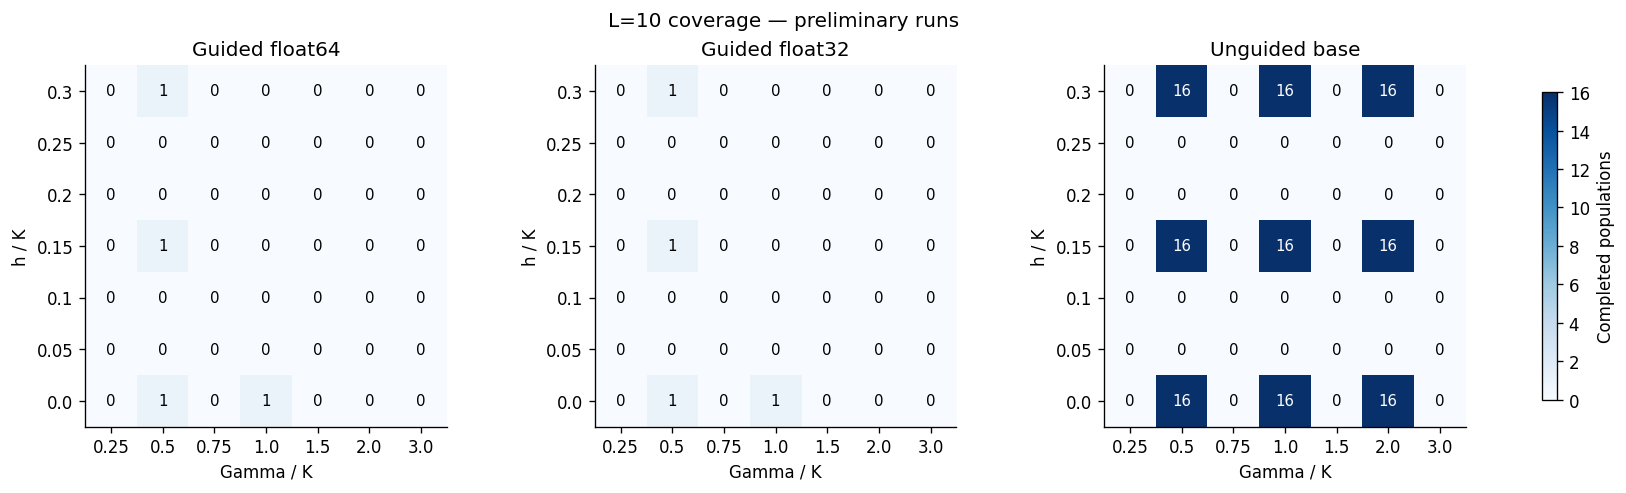

In [3]:
gammas=manifest['design']['gamma'];fields=manifest['design']['h']
fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
selections=[(guided[guided.precision=='float64'],'Guided float64'),
            (guided[guided.precision=='float32'],'Guided float32'),
            (unguided[unguided.setting=='base'],'Unguided base')]
for ax,(part,title) in zip(axes,selections):
    count=part.groupby(['h','gamma']).size()
    a=np.array([[count.get((h,g),0) for g in gammas] for h in fields])
    image=ax.imshow(a,origin='lower',cmap='Blues',vmin=0,vmax=16)
    for iy,ix in np.ndindex(a.shape):
        ax.text(ix,iy,str(a[iy,ix]),ha='center',va='center',color='white' if a[iy,ix]>8 else 'black',fontsize=9)
    ax.set(xticks=range(7),xticklabels=gammas,yticks=range(7),yticklabels=fields,
           xlabel='Gamma / K',ylabel='h / K',title=title)
fig.colorbar(image,ax=axes,label='Completed populations',shrink=.85)
fig.suptitle('L=10 coverage — preliminary runs')
save_figure(fig,'coverage')

## 2. Guided observables and matched unguided populations

All displayed points use the same disorder **60000**, repeat index 0, and base
settings: **W=32, equilibration 0.04, measurement 0.08, forward time 0.04,
two cycles, branch interval 0.02**. Seeds differ across methods and precisions.
There are no independent-repeat error bars. Differences between precisions mix
sampling noise with numerical effects and do not establish a precision bias.

The equal-time connected susceptibility is chi_conn = sum(C_ij squared)/N,
where C_ij is the connected spin correlation. We plot chi_conn/N. Finite-size
q_EA is the site average of squared local magnetization, estimated by signed
replica overlap; a noisy finite-run estimate may be negative. The 1/N line for
q2 is an independent-spin reference, not a phase boundary or convergence target.

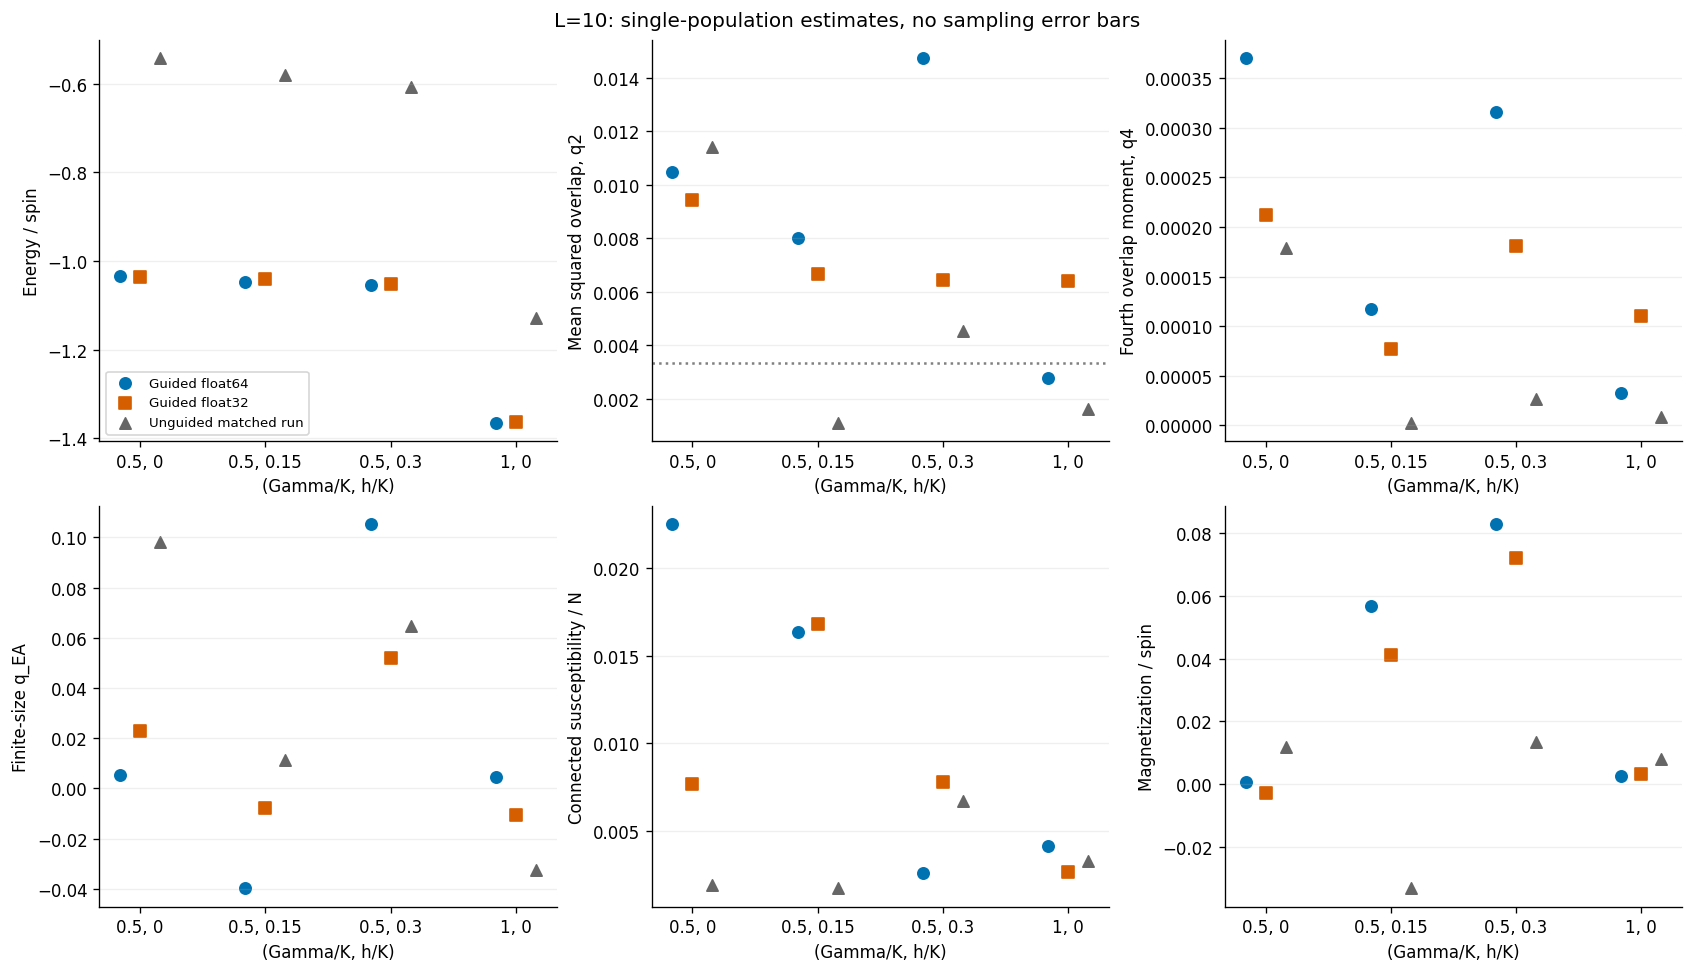

,method,precision,gamma,h,energy_per_site,q2,q_ea_finite,chi_connected_per_site,min_ess,max_lineage
494,constant,float64,0.5,0.00,-0.543004,0.011402,0.098229,0.001960,14.628571,0.12500
1042,network,float32,0.5,0.00,-1.035510,0.009417,0.023021,0.007716,21.333333,0.09375
470,network,float64,0.5,0.00,-1.034265,0.010488,0.005312,0.022519,21.333333,0.09375
325,constant,float64,0.5,0.15,-0.580348,0.001095,0.011354,0.001739,8.677966,0.21875
965,network,float32,0.5,0.15,-1.040163,0.006646,-0.007917,0.016790,24.380952,0.06250
840,network,float64,0.5,0.15,-1.048106,0.008019,-0.039792,0.016351,25.600000,0.09375
818,constant,float64,0.5,0.30,-0.607533,0.004547,0.064688,0.006719,11.130435,0.18750
202,network,float32,0.5,0.30,-1.050990,0.006424,0.051979,0.007776,25.600000,0.09375
736,network,float64,0.5,0.30,-1.053965,0.014725,0.105417,0.002611,20.480000,0.09375
573,constant,float64,1.0,0.00,-1.128494,0.001621,-0.032292,0.003295,7.757576,0.28125


In [4]:
contexts=sorted(set(zip(guided.gamma,guided.h)))
labels=[f'{g:g}, {h:g}' for g,h in contexts]
matched=unguided[(unguided.setting=='base')&(unguided.sample_id==60000)&(unguided.repeat==0)].copy()
matched=matched[[tuple(x) in contexts for x in matched[['gamma','h']].to_numpy()]]
comparison=pd.concat([guided,matched])
comparison.to_csv(TABLES/'matched_guided_comparison.csv',index=False)
panels=[('energy_per_site','Energy / spin'),('q2','Mean squared overlap, q2'),
        ('q4','Fourth overlap moment, q4'),('q_ea_finite','Finite-size q_EA'),
        ('chi_connected_per_site','Connected susceptibility / N'),('magnetization','Magnetization / spin')]
series=[(guided[guided.precision=='float64'],'Guided float64','o','#0072B2',-.16),
        (guided[guided.precision=='float32'],'Guided float32','s','#D55E00',0),
        (matched,'Unguided matched run','^','#666666',.16)]
fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
for ax,(obs,title) in zip(axes.flat,panels):
    for part,label,marker,color,offset in series:
        values=part.set_index(['gamma','h'])[obs].reindex(contexts).to_numpy()
        ax.scatter(np.arange(len(contexts))+offset,values,label=label,marker=marker,color=color,s=46)
    if obs=='q2':ax.axhline(1/300,color='gray',ls=':',label='1/N reference')
    ax.set(xticks=range(len(contexts)),xticklabels=labels,xlabel='(Gamma/K, h/K)',ylabel=title)
    ax.grid(axis='y',alpha=.2)
axes[0,0].legend(fontsize=8)
fig.suptitle('L=10: single-population estimates, no sampling error bars')
save_figure(fig,'guided_observables')
display(comparison[['method','precision','gamma','h','energy_per_site','q2','q_ea_finite',
    'chi_connected_per_site','min_ess','max_lineage']].sort_values(['gamma','h','method','precision']))

## 3. Unguided sensitivity to settings

Average four independent repeats **within each disorder first**, then average
the four disorder means. Error bars below are **one standard error across those
four disorder means**, including finite-run Monte Carlo scatter. They are
descriptive short-setting errors, not ground-state uncertainty or 95% intervals.
Cycles are not treated as independent repeats.

The plot shows the zero-field cut. CSV exports contain all nine field pairs.
These configurations are not a single monotone convergence ladder: time2/time4
change several times together, and combined changes population, cadence and
cycle count too. For a constant guide, initialization is already uniform, so
alternative_start is another independent ensemble at the time2 parameters.
No guided alternative-start runs completed in this archive.

,setting,W,tau_eq,tau_measure,tau_forward,cycles,branch,initial
0,base,32,0.04,0.08,0.04,2,0.02,guide
1,population64,64,0.04,0.08,0.04,2,0.02,guide
2,population128,128,0.04,0.08,0.04,2,0.02,guide
3,time2,64,0.08,0.16,0.08,2,0.02,guide
4,time4,64,0.16,0.32,0.16,2,0.02,guide
5,cadence,64,0.08,0.16,0.08,2,0.01,guide
6,combined,128,0.16,0.32,0.16,4,0.01,guide
7,alternative_start,64,0.08,0.16,0.08,2,0.02,uniform


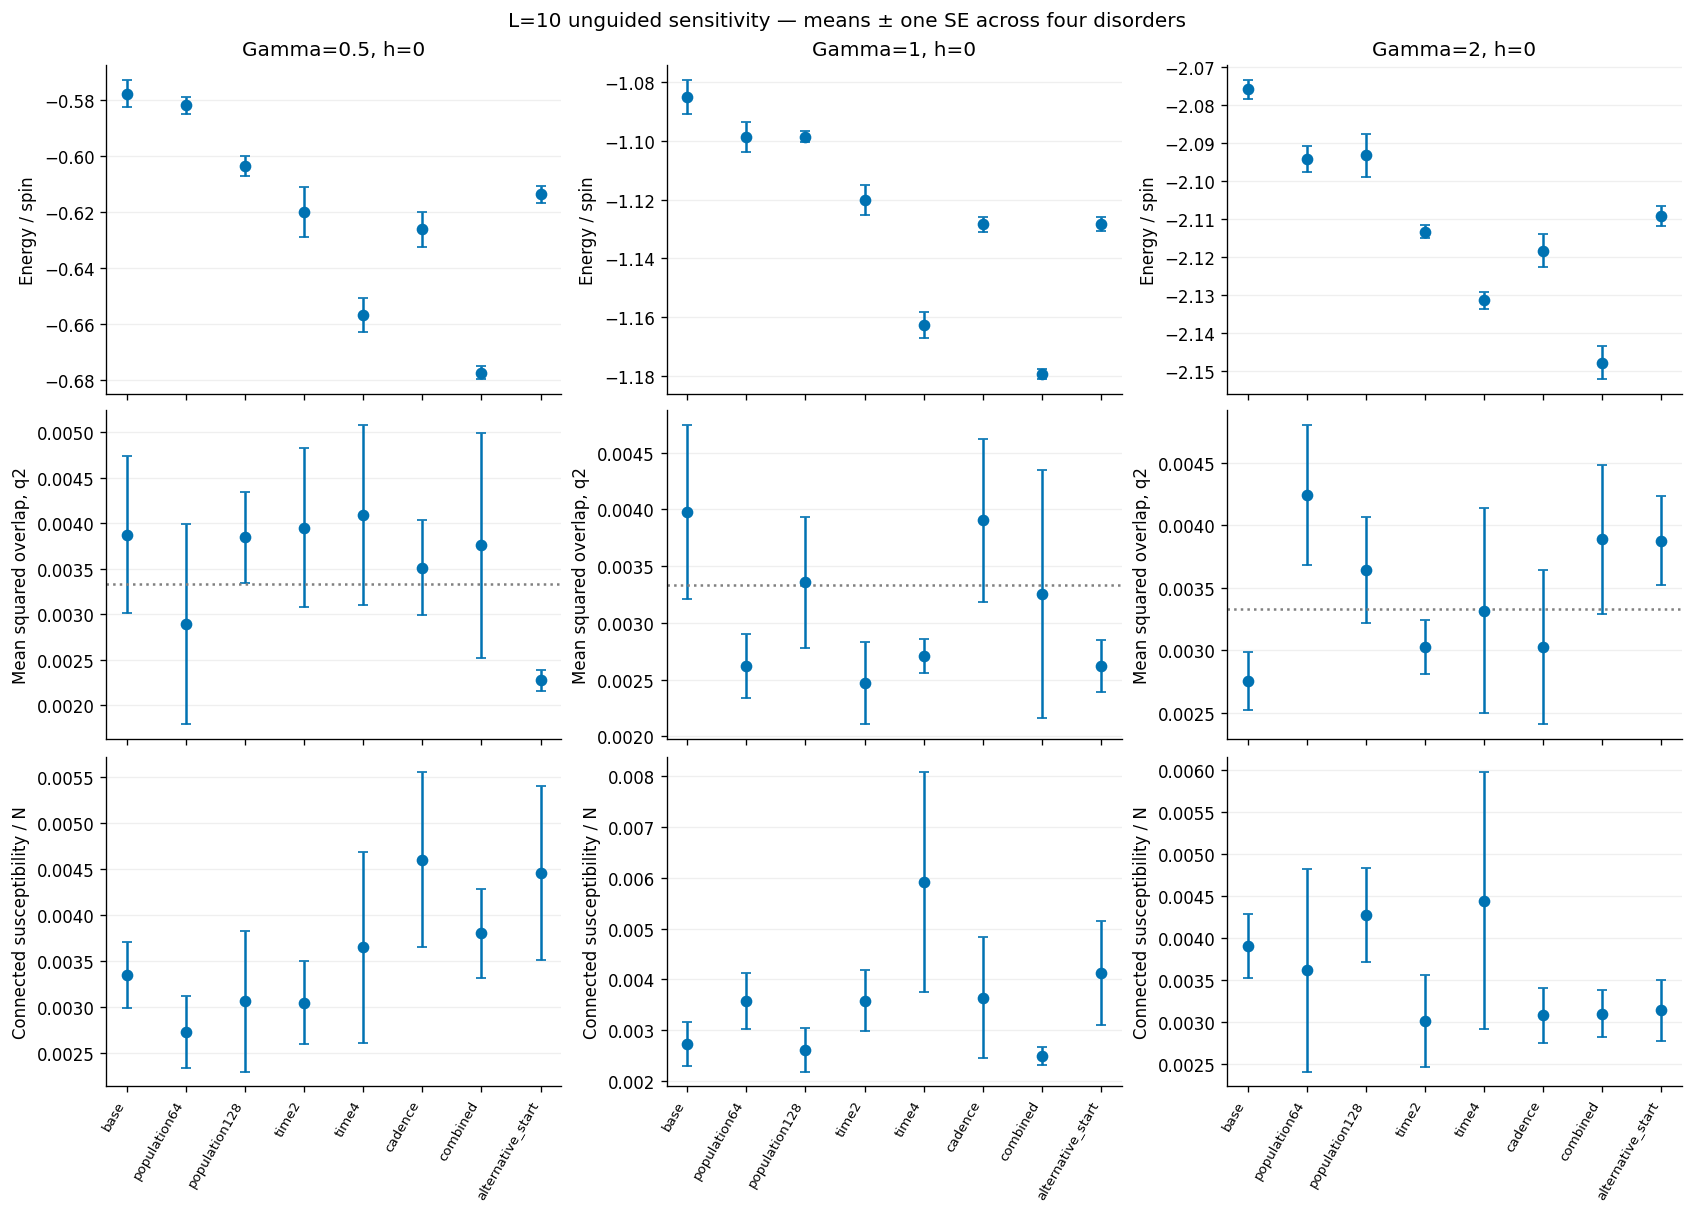

In [5]:
order=['base','population64','population128','time2','time4','cadence','combined','alternative_start']
configuration=df[['setting','W','tau_eq','tau_measure','tau_forward','cycles','branch','initial']].drop_duplicates()
configuration['setting']=pd.Categorical(configuration.setting,order,ordered=True)
display(configuration.sort_values('setting').reset_index(drop=True))
configuration.to_csv(TABLES/'settings.csv',index=False)
group=['setting','gamma','h','sample_id']
assert (unguided.groupby(group).size()==4).all(), 'Incomplete repeat coverage'
disorder=unguided.groupby(group)[observables].mean().reset_index()
assert (disorder.groupby(['setting','gamma','h']).size()==4).all(), 'Incomplete disorder coverage'
summary=disorder.groupby(['setting','gamma','h'])[observables].agg(['mean','sem'])
summary.columns=['_'.join(c) for c in summary.columns]
summary=summary.reset_index()
summary.to_csv(TABLES/'unguided_disorder_summary.csv',index=False)
disorder.to_csv(TABLES/'unguided_disorder_means.csv',index=False)
fig,axes=plt.subplots(3,3,figsize=(14,10),sharex=True,constrained_layout=True)
for col,g in enumerate([.5,1.,2.]):
    part=summary[(summary.gamma==g)&(summary.h==0)].set_index('setting').reindex(order)
    for row,(obs,label) in enumerate([('energy_per_site','Energy / spin'),('q2','Mean squared overlap, q2'),
                                     ('chi_connected_per_site','Connected susceptibility / N')]):
        ax=axes[row,col]
        ax.errorbar(range(8),part[obs+'_mean'],yerr=part[obs+'_sem'],fmt='o',capsize=3,color='#0072B2')
        if obs=='q2':ax.axhline(1/300,color='gray',ls=':')
        ax.set_ylabel(label);ax.grid(axis='y',alpha=.2)
        if row==0:ax.set_title(f'Gamma={g:g}, h=0')
        ax.set_xticks(range(8));ax.set_xticklabels(order,rotation=60,ha='right',fontsize=8)
fig.suptitle('L=10 unguided sensitivity — means ± one SE across four disorders')
save_figure(fig,'unguided_setting_sensitivity')

## 4. Ancestry diagnostics

An alarm means that **any cycle** has descendant ESS below 8 or a largest-lineage
fraction above 0.5. A healthy value is not an accuracy certificate. All alarm
cases are retained. Unguided fractions combine all nine fields and four disorders
with four repeats (144 runs per setting); guided points are individual populations.

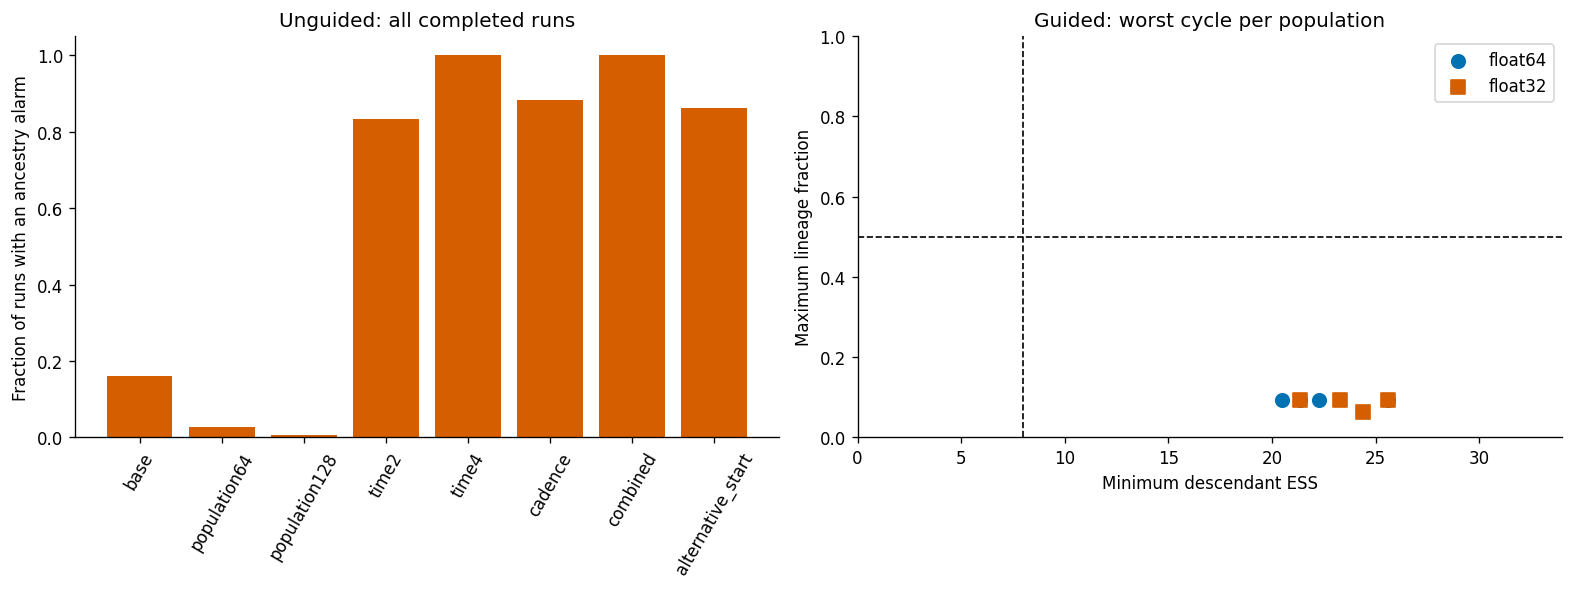

,runs,alarm_fraction,minimum_ess,median_ess,maximum_lineage
setting,,,,,
base,144,0.159722,3.555556,11.130435,0.500000
population64,144,0.027778,4.970874,18.285714,0.406250
population128,144,0.006944,7.223986,33.168167,0.351562
time2,144,0.833333,1.343832,4.691923,0.859375
time4,144,1.000000,1.000000,1.432677,1.000000
cadence,144,0.881944,1.174986,4.836060,0.921875
combined,144,1.000000,1.000000,1.321607,1.000000
alternative_start,144,0.861111,1.099893,5.171717,0.953125


In [6]:
alarm=unguided.groupby('setting').agg(runs=('id','size'),alarm_fraction=('alarm','mean'),
    minimum_ess=('min_ess','min'),median_ess=('min_ess','median'),maximum_lineage=('max_lineage','max')).reindex(order)
alarm.to_csv(TABLES/'ancestry_by_setting.csv')
fig,axes=plt.subplots(1,2,figsize=(13,4.8),constrained_layout=True)
axes[0].bar(range(8),alarm.alarm_fraction,color='#D55E00')
axes[0].set(xticks=range(8),xticklabels=order,ylim=(0,1.05),ylabel='Fraction of runs with an ancestry alarm',title='Unguided: all completed runs')
axes[0].tick_params(axis='x',rotation=60)
for precision,marker,color in [('float64','o','#0072B2'),('float32','s','#D55E00')]:
    part=guided[guided.precision==precision]
    axes[1].scatter(part.min_ess,part.max_lineage,label=precision,marker=marker,color=color,s=65)
axes[1].axvline(8,color='black',ls='--',lw=1);axes[1].axhline(.5,color='black',ls='--',lw=1)
axes[1].set(xlim=(0,34),ylim=(0,1),xlabel='Minimum descendant ESS',ylabel='Maximum lineage fraction',title='Guided: worst cycle per population')
axes[1].legend()
save_figure(fig,'ancestry_diagnostics')
display(alarm)

## 5. Recorded guided cost

Runtime sums execution-segment wall times. The float64 Gamma=0.5, h=0 run
resumed after a scheduler handoff and includes restart overhead. These are
independent short runs, not controlled equal-accuracy speedup measurements.
Memory is peak PyTorch allocation in the recorded segment, not total device
memory or a long-run capacity estimate.

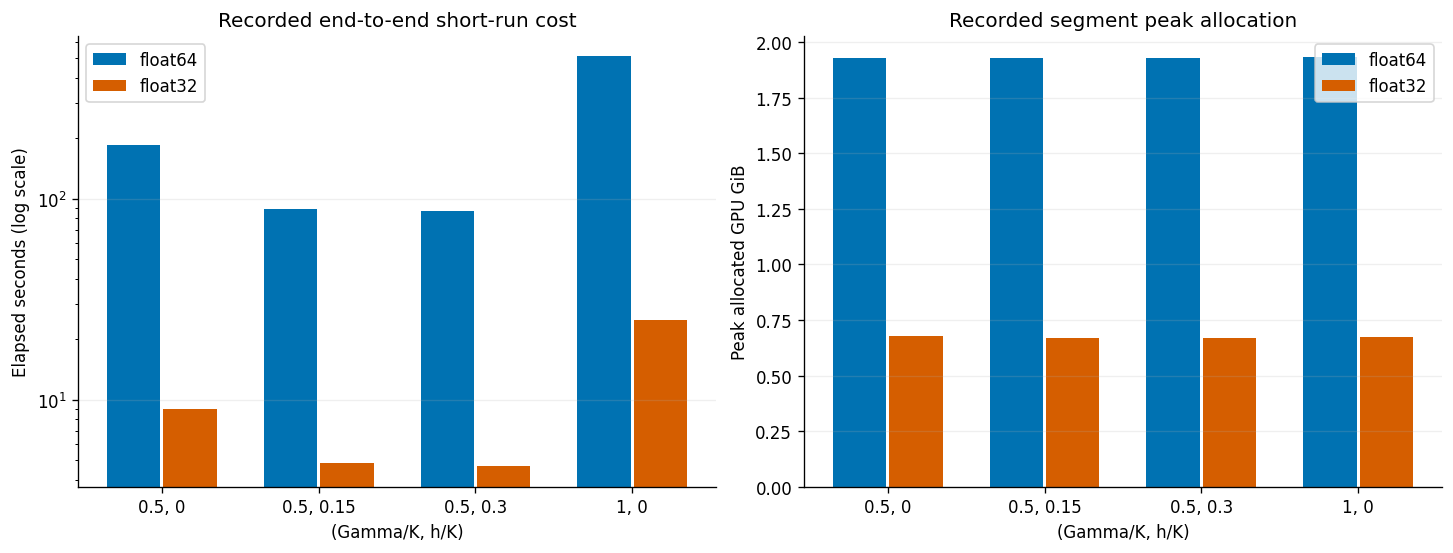

precision     float32     float64  observed_time_ratio_64_over_32
gamma h                                                          
0.5   0.00   8.987560  185.044698                       20.588981
      0.15   4.830811   88.467062                       18.313087
      0.30   4.678111   86.435195                       18.476516
1.0   0.00  24.830009  509.895143                       20.535440

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for precision,offset,color in [('float64',-.18,'#0072B2'),('float32',.18,'#D55E00')]:
    part=guided[guided.precision==precision].set_index(['gamma','h']).reindex(contexts)
    axes[0].bar(np.arange(len(contexts))+offset,part.seconds,width=.34,label=precision,color=color)
    axes[1].bar(np.arange(len(contexts))+offset,part.peak_mib/1024,width=.34,label=precision,color=color)
for ax in axes:
    ax.set(xticks=range(len(contexts)),xticklabels=labels,xlabel='(Gamma/K, h/K)')
    ax.legend();ax.grid(axis='y',alpha=.2)
axes[0].set(yscale='log',ylabel='Elapsed seconds (log scale)',title='Recorded end-to-end short-run cost')
axes[1].set(ylabel='Peak allocated GPU GiB',title='Recorded segment peak allocation')
save_figure(fig,'guided_cost')
cost=guided.pivot(index=['gamma','h'],columns='precision',values='seconds')
cost['observed_time_ratio_64_over_32']=cost.float64/cost.float32
display(cost)
cost.to_csv(TABLES/'guided_runtime_comparison.csv')

## 6. Guided float64 connected spectra

Each panel shows connected overlap spectrum / N for one population. The
reciprocal cell indices obey k=(mx*b1+my*b2)/L and include the stored kagome basis
phases. The origin equals chi_conn/N. The panels share a color scale and show
discrete momenta, not a real-space or phase map. Two forward cycles are
insufficient to infer ordering or critical behavior.

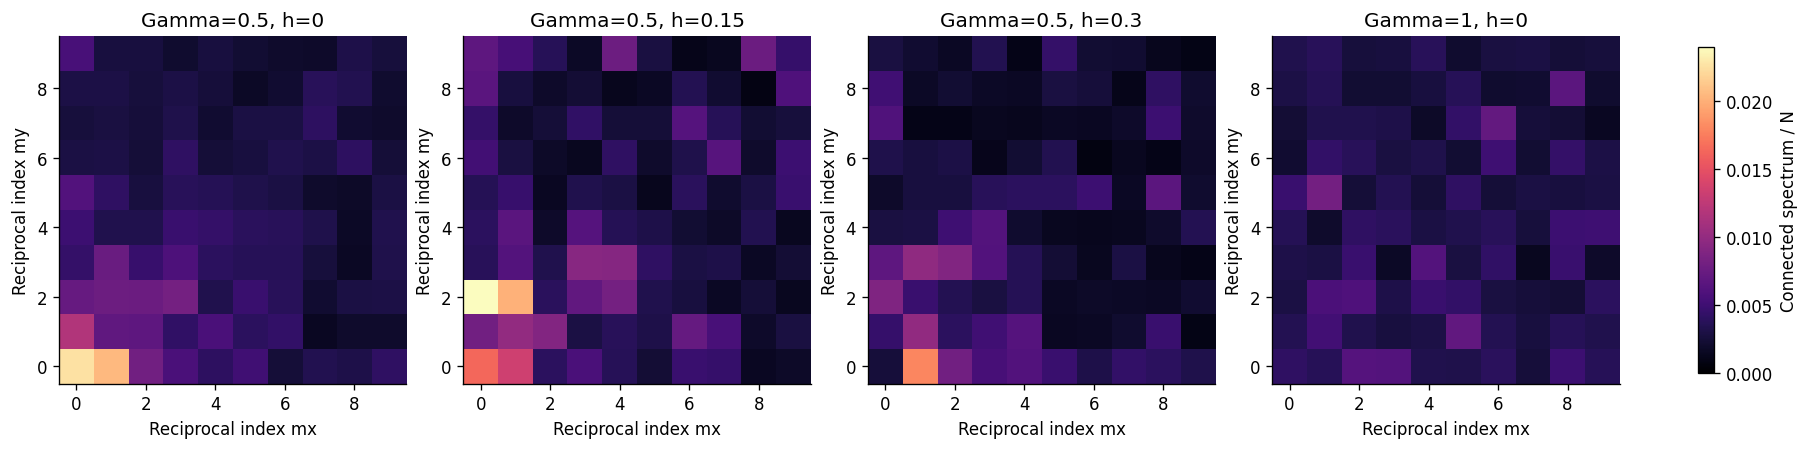

In [8]:
spectral=sorted([r for r in records if r['task']['method']=='network' and r['task']['precision']=='float64'],
    key=lambda r:(r['task']['gamma'],r['task']['h']))
arrays=[np.asarray(r['result']['connected_spectrum']).reshape(10,10)/300 for r in spectral]
fig,axes=plt.subplots(1,len(arrays),figsize=(15,4),constrained_layout=True,squeeze=False)
vmax=max(a.max() for a in arrays)
for ax,record,array in zip(axes.flat,spectral,arrays):
    t=record['task']
    im=ax.imshow(array,origin='lower',vmin=0,vmax=vmax,cmap='magma',interpolation='nearest')
    ax.set(title=f"Gamma={t['gamma']:g}, h={t['h']:g}",xlabel='Reciprocal index mx',ylabel='Reciprocal index my')
fig.colorbar(im,ax=list(axes.flat),label='Connected spectrum / N',shrink=.7)
save_figure(fig,'guided_connected_spectra')

## Interpretation and reproducibility

The frozen-guide projector executes at 300 spins under PBC, with structurally
valid replica observables and spectra. Guided coverage is sparse and lacks
independent-repeat uncertainty. Unguided setting sensitivity and ancestry loss
show why these short runs cannot qualify ground-state estimates. No spin-glass
phase or phase boundary can be inferred here. L=10 still requires the same
convergence and final-disorder standards as the other anchor sizes.

PNG/PDF figures: `figures/kagome_L10_gfmc/`.
CSV tables and per-input SHA-256 provenance: `data/kagome/transformer_af_l10_results/`.
Re-execute this notebook or run
`PYTHONPATH=code python3 -m transformer_qmc.report_l10_results` to regenerate.

In [9]:
display(Markdown(f"**Ancestry alarms:** {int(unguided.alarm.sum())}/{len(unguided)} unguided "
    f"and {int(guided.alarm.sum())}/{len(guided)} guided populations. All are retained."))
display(Markdown("**Main finding:** increasing the unguided forward times in `time4` and "
    "`combined` triggers ancestry alarms in every run in those settings. "
    "The eight guided short runs avoid those alarms, but their short forward time "
    "and single-population coverage do not demonstrate long-time accuracy."))
print('Figures:',FIGURES)
print('Tables and provenance:',TABLES)

**Ancestry alarms:** 687/1152 unguided and 0/8 guided populations. All are retained.

**Main finding:** increasing the unguided forward times in `time4` and `combined` triggers ancestry alarms in every run in those settings. The eight guided short runs avoid those alarms, but their short forward time and single-population coverage do not demonstrate long-time accuracy.

Figures: /Users/tianyiyan/Dropbox/spin-glasses/figures/kagome_L10_gfmc
Tables and provenance: /Users/tianyiyan/Dropbox/spin-glasses/data/kagome/transformer_af_l10_results
